# Projet 2 — Gestion de portefeuille & Backtesting

**Objectif :** Construire un portefeuille d'actions optimisé (Markowitz), mesurer son risque (VaR, CVaR, Monte Carlo) et tester une stratégie momentum sur la période 2020–2024.

**Actions :** Mix Europe + USA (Apple, JPMorgan, J&J, ExxonMobil, LVMH, TotalEnergies, BNP Paribas, SAP)

**Période :** 1er janvier 2020 — 31 décembre 2024

---

## 0. Installation et imports

In [1]:
!pip install yfinance pandas numpy matplotlib seaborn scipy --quiet


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Palette personnalisée
COLORS = ['#5B4FCF', '#E85D24', '#27AE60', '#F5A623', '#2980B9', '#8E44AD', '#16A085', '#C0392B']

print('Imports OK')

Imports OK


---
## PARTIE 1 — Données boursières

### Notion : Le rendement logarithmique

On télécharge les prix de clôture ajustés de 8 actions sur 2020–2024.  
On calcule ensuite les **rendements logarithmiques** :

$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$

Pourquoi logarithmique ?
- Il est **additif dans le temps** : rendement sur 2 jours = r1 + r2
- Il est **symétrique** : +50% puis -50% ≠ 0% en rendement simple, mais ≈ 0 en log
- C'est le **standard en finance quantitative**

In [3]:
# Définition des actions
tickers = {
    'Apple':         'AAPL',
    'JPMorgan':      'JPM',
    'J&J':           'JNJ',
    'ExxonMobil':    'XOM',
    'LVMH':          'MC.PA',
    'TotalEnergies': 'TTE.PA',
    'BNP Paribas':   'BNP.PA',
    'SAP':           'SAP.DE'
}

START = '2020-01-01'
END   = '2024-12-31'

# Téléchargement des prix
print('Téléchargement des données...')
raw = yf.download(list(tickers.values()), start=START, end=END, auto_adjust=True)['Close']
raw.columns = list(tickers.keys())
raw = raw.dropna()

print(f'\nDonnées chargées : {raw.shape[0]} jours de cotation, {raw.shape[1]} actions')
print(f'Période : {raw.index[0].date()} → {raw.index[-1].date()}')
raw.tail(3)

Téléchargement des données...


[*********************100%***********************]  8 of 8 completed


Données chargées : 1241 jours de cotation, 8 actions
Période : 2020-01-02 → 2024-12-30


,Apple,JPMorgan,J&J,ExxonMobil,LVMH,TotalEnergies,BNP Paribas,SAP
Date,,,,,,,,
2024-12-23,253.430878,49.055077,138.723969,230.179611,604.605164,230.323807,46.976723,100.520256
2024-12-27,253.748550,49.994499,138.513870,232.863876,610.754944,233.393478,47.792141,100.690475
2024-12-30,250.382950,50.156761,136.880905,231.077591,604.701172,230.275070,47.656231,100.009621


In [4]:
# Calcul des rendements logarithmiques
returns = np.log(raw / raw.shift(1)).dropna()

print('Statistiques des rendements journaliers :')
stats = pd.DataFrame({
    'Rendement moyen (%)': (returns.mean() * 100).round(3),
    'Volatilité (%)':      (returns.std()  * 100).round(3),
    'Min (%)':             (returns.min()  * 100).round(3),
    'Max (%)':             (returns.max()  * 100).round(3),
})
print(stats.to_string())

Statistiques des rendements journaliers :
               Rendement moyen (%)  Volatilité (%)  Min (%)  Max (%)
Apple                        0.100           2.012  -13.771   11.316
JPMorgan                     0.028           2.282  -14.526   16.535
J&J                          0.010           1.235   -7.578    7.694
ExxonMobil                   0.054           2.063  -16.211   16.562
LVMH                         0.039           1.906   -9.078   12.055
TotalEnergies                0.060           1.751  -24.766    7.504
BNP Paribas                  0.030           2.043  -18.162   14.041
SAP                          0.052           2.176  -13.039   11.944


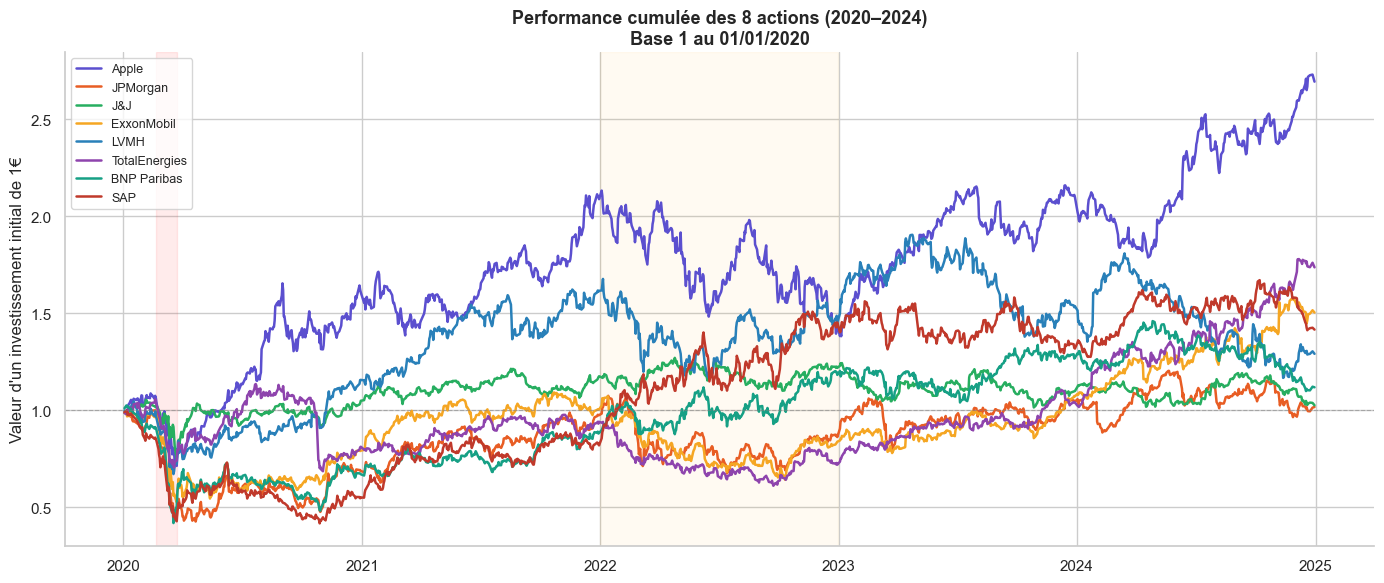


Performance totale 2020–2024 :
Apple            169.4
TotalEnergies     73.7
ExxonMobil        50.4
SAP               41.6
LVMH              29.2
BNP Paribas       11.9
J&J                2.6
JPMorgan           1.8


In [5]:
# Performance cumulée de chaque action
cumulative = (1 + returns).cumprod()

fig, ax = plt.subplots(figsize=(14, 6))
for i, col in enumerate(cumulative.columns):
    ax.plot(cumulative.index, cumulative[col], label=col,
            color=COLORS[i], linewidth=1.8)

ax.axhline(y=1, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
ax.set_title('Performance cumulée des 8 actions (2020–2024)\nBase 1 au 01/01/2020',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Valeur d\'un investissement initial de 1€')
ax.legend(loc='upper left', fontsize=9)

# Annotations COVID et hausse des taux
ax.axvspan('2020-02-20', '2020-03-23', alpha=0.08, color='red', label='Crash COVID')
ax.axvspan('2022-01-01', '2022-12-31', alpha=0.05, color='orange', label='Hausse des taux')

plt.tight_layout()
plt.savefig('performance_cumulee.png', dpi=150, bbox_inches='tight')
plt.show()

# Performance totale
perf_totale = (cumulative.iloc[-1] - 1) * 100
print('\nPerformance totale 2020–2024 :')
print(perf_totale.sort_values(ascending=False).round(1).to_string())

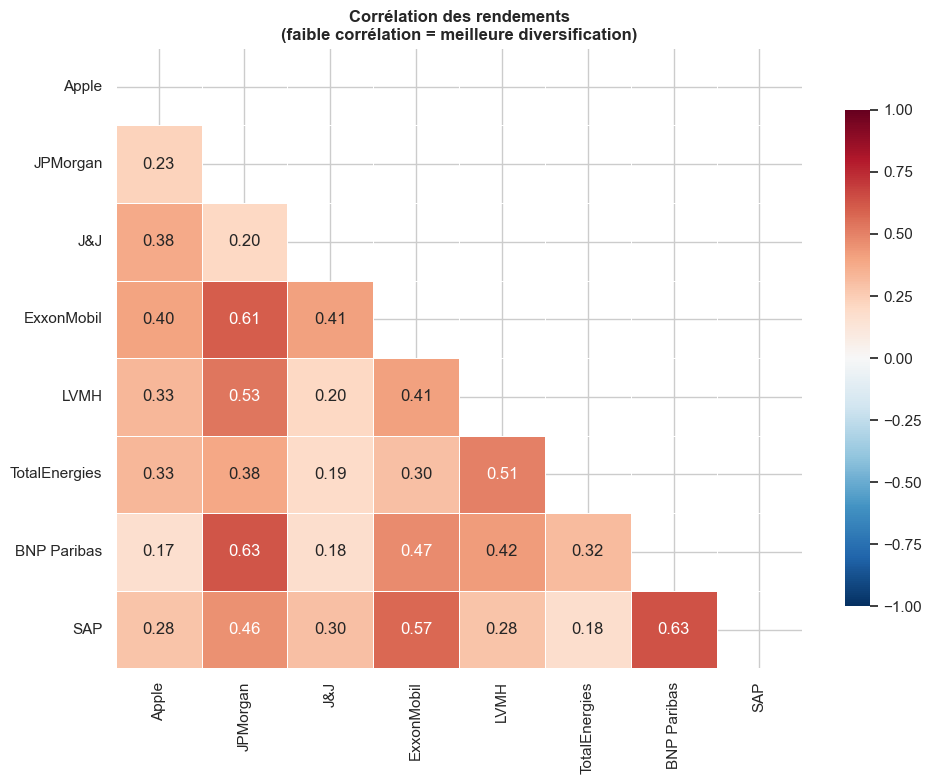

In [6]:
# Matrice de corrélation des rendements
corr = returns.corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax,
            linewidths=0.5, cbar_kws={'shrink': 0.8})
ax.set_title('Corrélation des rendements\n(faible corrélation = meilleure diversification)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_rendements.png', dpi=150, bbox_inches='tight')
plt.show()

### Observations — Données boursières
- Apple : meilleure performance (+169%) mais forte volatilité (2.0%)
- J&J et JPMorgan : performances décevantes (+2.6% et +1.8%) 
  mais faibles corrélations → utiles pour la diversification
- Crash COVID visible en mars 2020 : corrélations temporairement 
  toutes à 1 (risque systémique)
- JPMorgan/BNP (0.63) et ExxonMobil/SAP (0.57) : paires 
  les plus corrélées --> Markowitz les sous-pondèrera
- Aucune corrélation négative : diversification imparfaite 
  mais acceptable sur ce mix sectoriel

---
## PARTIE 2 — Optimisation Markowitz

### Notion : La frontière efficiente

Markowitz a montré qu'il existe une infinité de portefeuilles possibles (en changeant les poids de chaque action).  
La **frontière efficiente** regroupe les meilleurs portefeuilles :
- Pour un risque donné → maximum de rendement
- Pour un rendement donné → minimum de risque

On cherche le portefeuille qui **maximise le ratio de Sharpe** :
$$\text{Sharpe} = \frac{R_p - R_f}{\sigma_p}$$
où $R_f$ = taux sans risque (2% annualisé ici), $\sigma_p$ = volatilité du portefeuille

In [7]:
# Paramètres annualisés
N_JOURS = 252         # jours de cotation par an
TAUX_RF = 0.02        # taux sans risque annualisé (2%)
N_ACTIONS = len(returns.columns)

mu    = returns.mean() * N_JOURS           # rendements annuels espérés
sigma = returns.cov()  * N_JOURS           # matrice de covariance annualisée

def portfolio_perf(weights, mu, sigma):
    """Calcule rendement, volatilité et Sharpe d'un portefeuille."""
    ret = np.dot(weights, mu)
    vol = np.sqrt(np.dot(weights, np.dot(sigma, weights)))
    sharpe = (ret - TAUX_RF) / vol
    return ret, vol, sharpe

# Simulation de 10 000 portefeuilles aléatoires
N_SIMUL = 10_000
resultats = np.zeros((N_SIMUL, 3 + N_ACTIONS))

np.random.seed(42)
for i in range(N_SIMUL):
    w = np.random.dirichlet(np.ones(N_ACTIONS))  # poids aléatoires qui somment à 1
    ret, vol, sharpe = portfolio_perf(w, mu, sigma)
    resultats[i, :3] = [ret, vol, sharpe]
    resultats[i, 3:] = w

cols = ['Rendement', 'Volatilite', 'Sharpe'] + list(returns.columns)
df_simul = pd.DataFrame(resultats, columns=cols)

print(f'{N_SIMUL:,} portefeuilles simulés')
print(f'Sharpe max parmi les simulations : {df_simul["Sharpe"].max():.3f}')

10,000 portefeuilles simulés
Sharpe max parmi les simulations : 0.740


In [8]:
# Optimisation numérique — portefeuille Maximum Sharpe
def neg_sharpe(weights):
    return -portfolio_perf(weights, mu, sigma)[2]

contraintes = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1})  # somme des poids = 1
bornes = tuple((0, 1) for _ in range(N_ACTIONS))                 # pas de vente à découvert
w0 = np.array([1/N_ACTIONS] * N_ACTIONS)                         # départ : équipondéré

res = minimize(neg_sharpe, w0, method='SLSQP',
               bounds=bornes, constraints=contraintes)

w_opt = res.x
ret_opt, vol_opt, sharpe_opt = portfolio_perf(w_opt, mu, sigma)

print('=== Portefeuille optimal (Maximum Sharpe) ===')
print(f'Rendement annualisé : {ret_opt:.1%}')
print(f'Volatilité annualisée : {vol_opt:.1%}')
print(f'Ratio de Sharpe : {sharpe_opt:.3f}')
print('\nPoids optimaux :')
poids_df = pd.Series(w_opt, index=returns.columns).sort_values(ascending=False)
for action, poids in poids_df.items():
    print(f'  {action:<15} {poids:.1%}')

=== Portefeuille optimal (Maximum Sharpe) ===
Rendement annualisé : 21.2%
Volatilité annualisée : 24.7%
Ratio de Sharpe : 0.776

Poids optimaux :
  Apple           61.5%
  TotalEnergies   29.2%
  SAP             9.3%
  J&J             0.0%
  ExxonMobil      0.0%
  JPMorgan        0.0%
  LVMH            0.0%
  BNP Paribas     0.0%


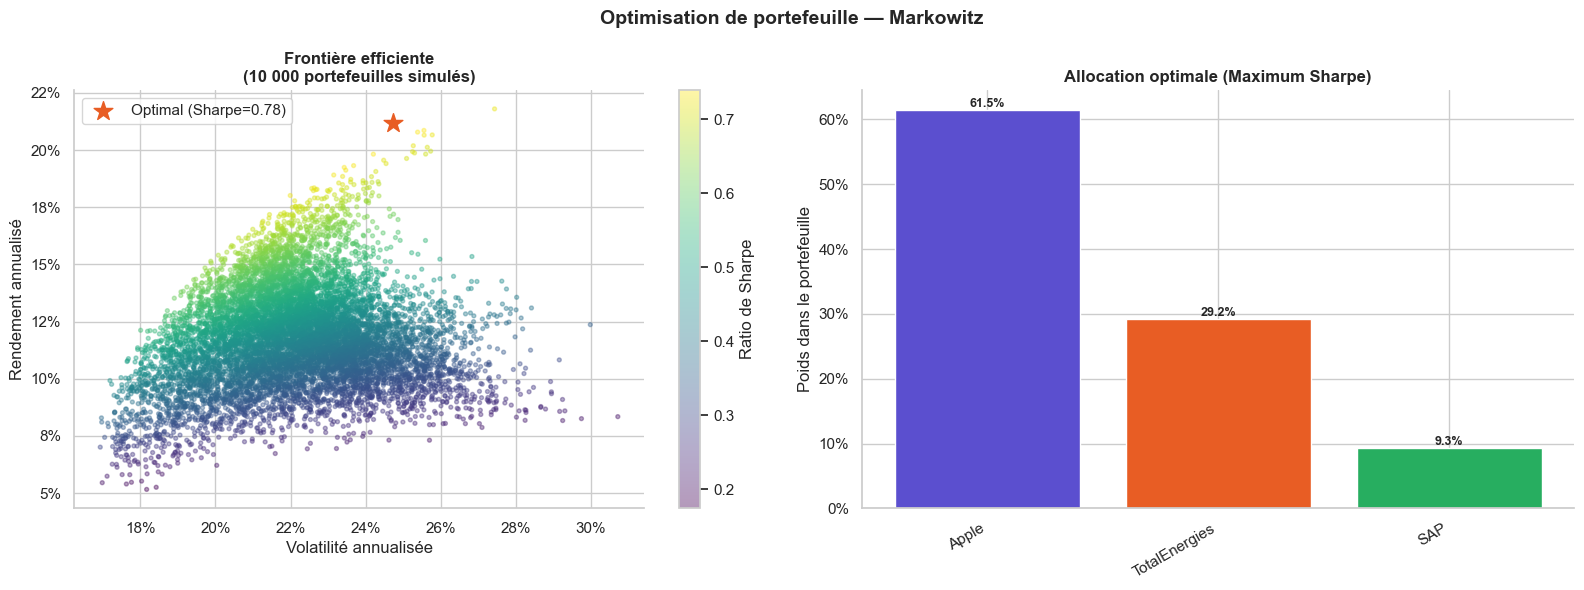

In [9]:
# Frontière efficiente
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Graphique 1 : nuage de portefeuilles + optimal
ax = axes[0]
sc = ax.scatter(df_simul['Volatilite'], df_simul['Rendement'],
                c=df_simul['Sharpe'], cmap='viridis', alpha=0.4, s=8)
plt.colorbar(sc, ax=ax, label='Ratio de Sharpe')
ax.scatter(vol_opt, ret_opt, color='#E85D24', s=200, zorder=5,
           marker='*', label=f'Optimal (Sharpe={sharpe_opt:.2f})')
ax.set_xlabel('Volatilité annualisée')
ax.set_ylabel('Rendement annualisé')
ax.set_title('Frontière efficiente\n(10 000 portefeuilles simulés)', fontweight='bold')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
ax.legend()

# Graphique 2 : poids du portefeuille optimal
ax2 = axes[1]
poids_plot = poids_df[poids_df > 0.001]
bars = ax2.bar(range(len(poids_plot)), poids_plot.values,
               color=COLORS[:len(poids_plot)])
ax2.set_xticks(range(len(poids_plot)))
ax2.set_xticklabels(poids_plot.index, rotation=30, ha='right')
ax2.set_ylabel('Poids dans le portefeuille')
ax2.set_title('Allocation optimale (Maximum Sharpe)', fontweight='bold')
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
for bar, val in zip(bars, poids_plot.values):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.005,
             f'{val:.1%}', ha='center', fontsize=9, fontweight='bold')

plt.suptitle('Optimisation de portefeuille — Markowitz', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('markowitz.png', dpi=150, bbox_inches='tight')
plt.show()

### Observations — Markowitz
- Portefeuille optimal concentré sur 3 actions (Apple 61.5%, 
  TotalEnergies 29.2%, SAP 9.3%) : Markowitz élimine les actions 
  à faible rendement même si elles diversifient bien
- Sharpe = 0.776 : bon ratio risque/rendement
- Limite principale : sur-optimisation sur données historiques 
  (look-ahead bias); en pratique, contraintes de concentration 
  réglementaires limiteraient le poids d'Apple à ~20-30%
- JPMorgan et BNP éliminés malgré leurs faibles corrélations : 
  rendement insuffisant pour justifier leur volatilité

---
## PARTIE 3 — Mesure du risque : VaR et CVaR

### Notion : VaR, CVaR et Monte Carlo

**VaR à 95%** = perte maximale dans 95% des scénarios. Formellement :
$$VaR_{95\%} = -Q_{5\%}(R_p)$$
où $Q_{5\%}$ est le 5ème percentile des rendements du portefeuille.

**CVaR (Expected Shortfall)** = perte moyenne dans les 5% pires cas :
$$CVaR_{95\%} = -E[R_p \mid R_p < -VaR_{95\%}]$$

**Monte Carlo** = simuler des milliers de scénarios futurs possibles pour estimer la distribution des pertes.  
C'est la méthode la plus puissante — et celle que les Quant Researchers utilisent en vrai.

In [10]:
# Rendements du portefeuille optimal
port_returns = returns.dot(w_opt)

CONFIANCE = 0.95
INVESTISSEMENT = 100_000  # 100 000 €

# VaR et CVaR historiques
var_hist  = -np.percentile(port_returns, (1 - CONFIANCE) * 100)
cvar_hist = -port_returns[port_returns < -var_hist].mean()

print('=== VaR et CVaR historiques (95%) ===')
print(f'VaR  journalière : {var_hist:.2%}  →  {var_hist * INVESTISSEMENT:,.0f}€ sur 100 000€')
print(f'CVaR journalière : {cvar_hist:.2%}  →  {cvar_hist * INVESTISSEMENT:,.0f}€ sur 100 000€')
print()
print('Interprétation :')
print(f'  Dans 95% des cas, on ne perd pas plus de {var_hist:.2%} par jour.')
print(f'  Dans les 5% pires jours, on perd en moyenne {cvar_hist:.2%}.')

=== VaR et CVaR historiques (95%) ===
VaR  journalière : 2.26%  →  2,262€ sur 100 000€
CVaR journalière : 3.65%  →  3,652€ sur 100 000€

Interprétation :
  Dans 95% des cas, on ne perd pas plus de 2.26% par jour.
  Dans les 5% pires jours, on perd en moyenne 3.65%.


In [11]:
# Monte Carlo — simulation de 10 000 scénarios sur 252 jours
N_SIMUL_MC = 10_000
N_JOURS_MC = 252

mu_port  = port_returns.mean()
std_port = port_returns.std()

np.random.seed(42)
# Simulation des rendements futurs (distribution normale)
simul_rendements = np.random.normal(mu_port, std_port, (N_SIMUL_MC, N_JOURS_MC))
# Valeur du portefeuille au fil du temps
simul_valeurs = INVESTISSEMENT * np.cumprod(1 + simul_rendements, axis=1)

# Résultats à 1 an
valeurs_finales = simul_valeurs[:, -1]
gains_pertes    = valeurs_finales - INVESTISSEMENT

var_mc  = -np.percentile(gains_pertes, (1 - CONFIANCE) * 100)
cvar_mc = -gains_pertes[gains_pertes < -var_mc].mean()

print('=== Monte Carlo — horizon 1 an (95%) ===')
print(f'Valeur médiane dans 1 an    : {np.median(valeurs_finales):,.0f}€')
print(f'Valeur moyenne dans 1 an    : {np.mean(valeurs_finales):,.0f}€')
print(f'Pire cas (1%)               : {np.percentile(valeurs_finales, 1):,.0f}€')
print(f'Meilleur cas (99%)          : {np.percentile(valeurs_finales, 99):,.0f}€')
print(f'VaR annuelle (95%)          : {var_mc:,.0f}€')
print(f'CVaR annuelle (95%)         : {cvar_mc:,.0f}€')

=== Monte Carlo — horizon 1 an (95%) ===
Valeur médiane dans 1 an    : 119,660€
Valeur moyenne dans 1 an    : 123,283€
Pire cas (1%)               : 67,309€
Meilleur cas (99%)          : 212,023€
VaR annuelle (95%)          : 20,700€
CVaR annuelle (95%)         : 28,150€


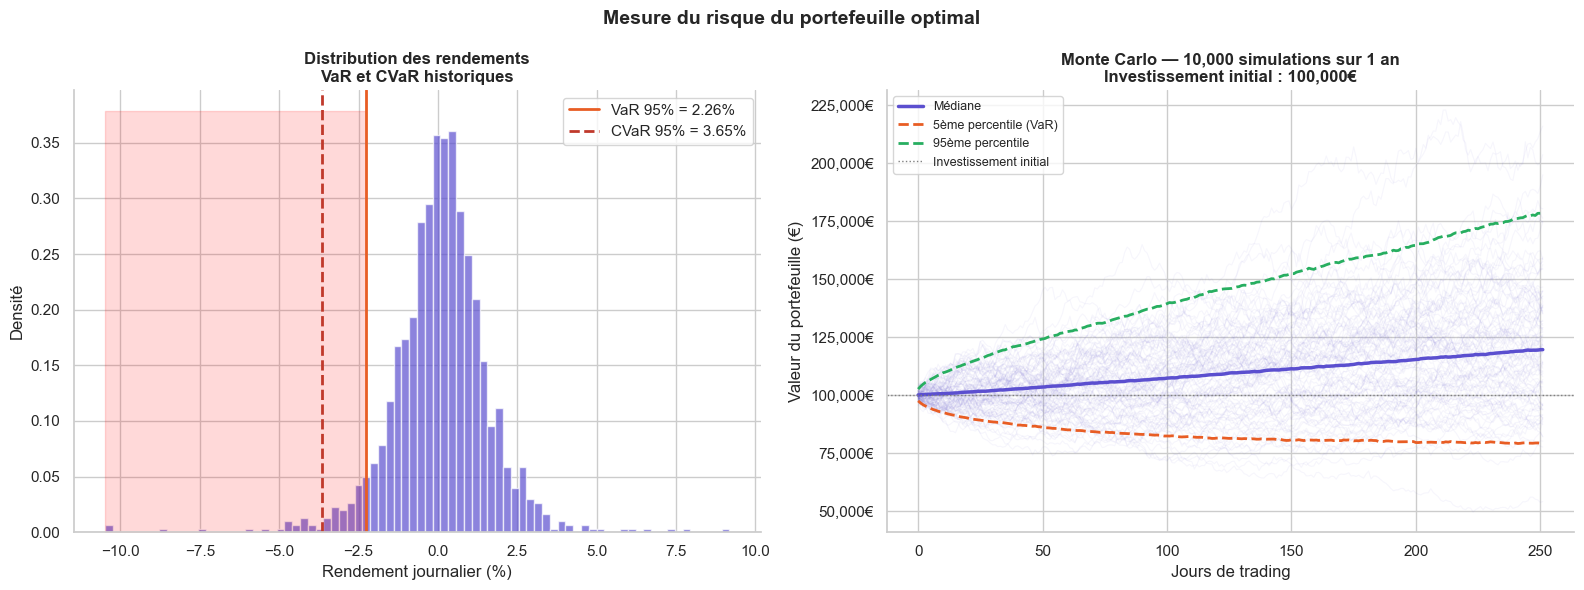

In [12]:
# Visualisations risque
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Distribution des rendements historiques + VaR
ax = axes[0]
ax.hist(port_returns * 100, bins=80, color='#5B4FCF', alpha=0.7, density=True)
ax.axvline(-var_hist * 100, color='#E85D24', linewidth=2,
           label=f'VaR 95% = {var_hist:.2%}')
ax.axvline(-cvar_hist * 100, color='#C0392B', linewidth=2, linestyle='--',
           label=f'CVaR 95% = {cvar_hist:.2%}')
ax.fill_betweenx([0, ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 20],
                 port_returns.min() * 100, -var_hist * 100,
                 alpha=0.15, color='red')
ax.set_xlabel('Rendement journalier (%)')
ax.set_ylabel('Densité')
ax.set_title('Distribution des rendements\nVaR et CVaR historiques', fontweight='bold')
ax.legend()

# Monte Carlo — 100 trajectoires + intervalles
ax2 = axes[1]
jours = np.arange(N_JOURS_MC)
for i in range(100):
    ax2.plot(jours, simul_valeurs[i], alpha=0.05, color='#5B4FCF', linewidth=0.8)
ax2.plot(jours, np.percentile(simul_valeurs, 50, axis=0),
         color='#5B4FCF', linewidth=2.5, label='Médiane')
ax2.plot(jours, np.percentile(simul_valeurs, 5, axis=0),
         color='#E85D24', linewidth=2, linestyle='--', label='5ème percentile (VaR)')
ax2.plot(jours, np.percentile(simul_valeurs, 95, axis=0),
         color='#27AE60', linewidth=2, linestyle='--', label='95ème percentile')
ax2.axhline(y=INVESTISSEMENT, color='gray', linewidth=1, linestyle=':',
            label='Investissement initial')
ax2.set_xlabel('Jours de trading')
ax2.set_ylabel('Valeur du portefeuille (€)')
ax2.set_title(f'Monte Carlo — {N_SIMUL_MC:,} simulations sur 1 an\nInvestissement initial : {INVESTISSEMENT:,}€',
              fontweight='bold')
ax2.legend(fontsize=9)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}€'))

plt.suptitle('Mesure du risque du portefeuille optimal', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('risk_measures.png', dpi=150, bbox_inches='tight')
plt.show()

### Observations — VaR, CVaR et Monte Carlo
- VaR journalière 95% = 2.26% (2 262€/100 000€) : 
  1 jour sur 20, on dépasse cette perte
- CVaR = 3.65% > VaR × 1.6 : fat tails confirmés — 
  la distribution normale sous-estime le risque réel
- Distribution asymétrique (skewness négatif) : 
  les grosses pertes sont plus probables que prévu
- Monte Carlo (10 000 simulations) : 
  médiane +19.6%, pire cas (1%) -32.7% sur 1 an
- VaR annuelle 95% = 20 700€ : cohérent avec 
  Bâle III qui exige ce calcul pour le capital réglementaire
- Limite : Monte Carlo suppose une distribution normale 
  des rendements — en pratique les queues sont plus épaisses

---
## PARTIE 4 — Stratégie Momentum & Backtesting

### Notion : Momentum et backtesting

**Stratégie momentum** : chaque mois, on classe les 8 actions selon leur performance des 3 derniers mois.  
On achète les **3 meilleures** (top 3) et on "vend" les 3 moins bonnes (on les ignore).

**Backtesting** : on simule cette stratégie sur 2020–2024 comme si on l'avait appliquée en vrai.  
On compare ensuite avec une **stratégie passive** : acheter le portefeuille équipondéré et ne rien faire.

**Métriques d'évaluation :**
- **Rendement annualisé** : gain moyen par an
- **Volatilité annualisée** : risque moyen par an  
- **Ratio de Sharpe** : rendement par unité de risque
- **Max Drawdown** : perte maximale depuis un pic — "combien j'aurais perdu au pire moment ?"

In [13]:
# Rééchantillonnage mensuel
returns_monthly = returns.resample('ME').sum()   # rendements mensuels

# Stratégie momentum : top 3 actions sur les 3 derniers mois
LOOKBACK = 3   # fenêtre de momentum en mois
TOP_N    = 3   # nombre d'actions à sélectionner

momentum_returns = []
passive_returns  = []
dates_bt         = []
selections       = []

for i in range(LOOKBACK, len(returns_monthly)):
    # Rendement cumulé sur la fenêtre de lookback
    lookback_perf = returns_monthly.iloc[i-LOOKBACK:i].sum()

    # Sélection des top N actions
    top_actions = lookback_perf.nlargest(TOP_N).index.tolist()
    w_momentum  = np.array([1/TOP_N if a in top_actions else 0
                            for a in returns.columns])
    w_passive   = np.ones(N_ACTIONS) / N_ACTIONS

    # Rendement du mois suivant
    r_next = returns_monthly.iloc[i]
    momentum_returns.append(np.dot(w_momentum, r_next))
    passive_returns.append(np.dot(w_passive, r_next))
    dates_bt.append(returns_monthly.index[i])
    selections.append(', '.join(top_actions))

# Création du DataFrame de backtesting
bt = pd.DataFrame({
    'momentum': momentum_returns,
    'passive':  passive_returns,
    'selection': selections
}, index=dates_bt)

print(f'Backtesting sur {len(bt)} mois ({bt.index[0].date()} → {bt.index[-1].date()}')
print('\nExemple de sélections momentum :')
print(bt[['selection']].head(6).to_string())

Backtesting sur 57 mois (2020-04-30 → 2024-12-31

Exemple de sélections momentum :
                                 selection
2020-04-30       J&J, Apple, TotalEnergies
2020-05-31       J&J, Apple, TotalEnergies
2020-06-30       Apple, J&J, TotalEnergies
2020-07-31  Apple, JPMorgan, TotalEnergies
2020-08-31  Apple, TotalEnergies, JPMorgan
2020-09-30  Apple, TotalEnergies, JPMorgan


In [14]:
# Calcul des métriques de performance
def metrics(r, rf=TAUX_RF/12):
    """Calcule les métriques de performance d'une stratégie."""
    cumul      = (1 + r).cumprod()
    ret_annual = (cumul.iloc[-1]) ** (12 / len(r)) - 1
    vol_annual = r.std() * np.sqrt(12)
    sharpe     = (ret_annual - TAUX_RF) / vol_annual

    # Max Drawdown
    rolling_max = cumul.cummax()
    drawdown    = (cumul - rolling_max) / rolling_max
    max_dd      = drawdown.min()

    return {
        'Rendement annualisé': f'{ret_annual:.2%}',
        'Volatilité annualisée': f'{vol_annual:.2%}',
        'Ratio de Sharpe': f'{sharpe:.3f}',
        'Max Drawdown': f'{max_dd:.2%}',
        'Performance totale': f'{(cumul.iloc[-1] - 1):.2%}'
    }

perf_mom = metrics(pd.Series(bt['momentum']))
perf_pas = metrics(pd.Series(bt['passive']))

comparaison = pd.DataFrame({'Momentum': perf_mom, 'Passive (équipondérée)': perf_pas})
print('=== Comparaison des stratégies ===')
print(comparaison.to_string())

=== Comparaison des stratégies ===
                      Momentum Passive (équipondérée)
Rendement annualisé     19.88%                 19.30%
Volatilité annualisée   22.00%                 17.32%
Ratio de Sharpe          0.812                  0.999
Max Drawdown           -25.86%                -15.74%
Performance totale     136.59%                131.24%


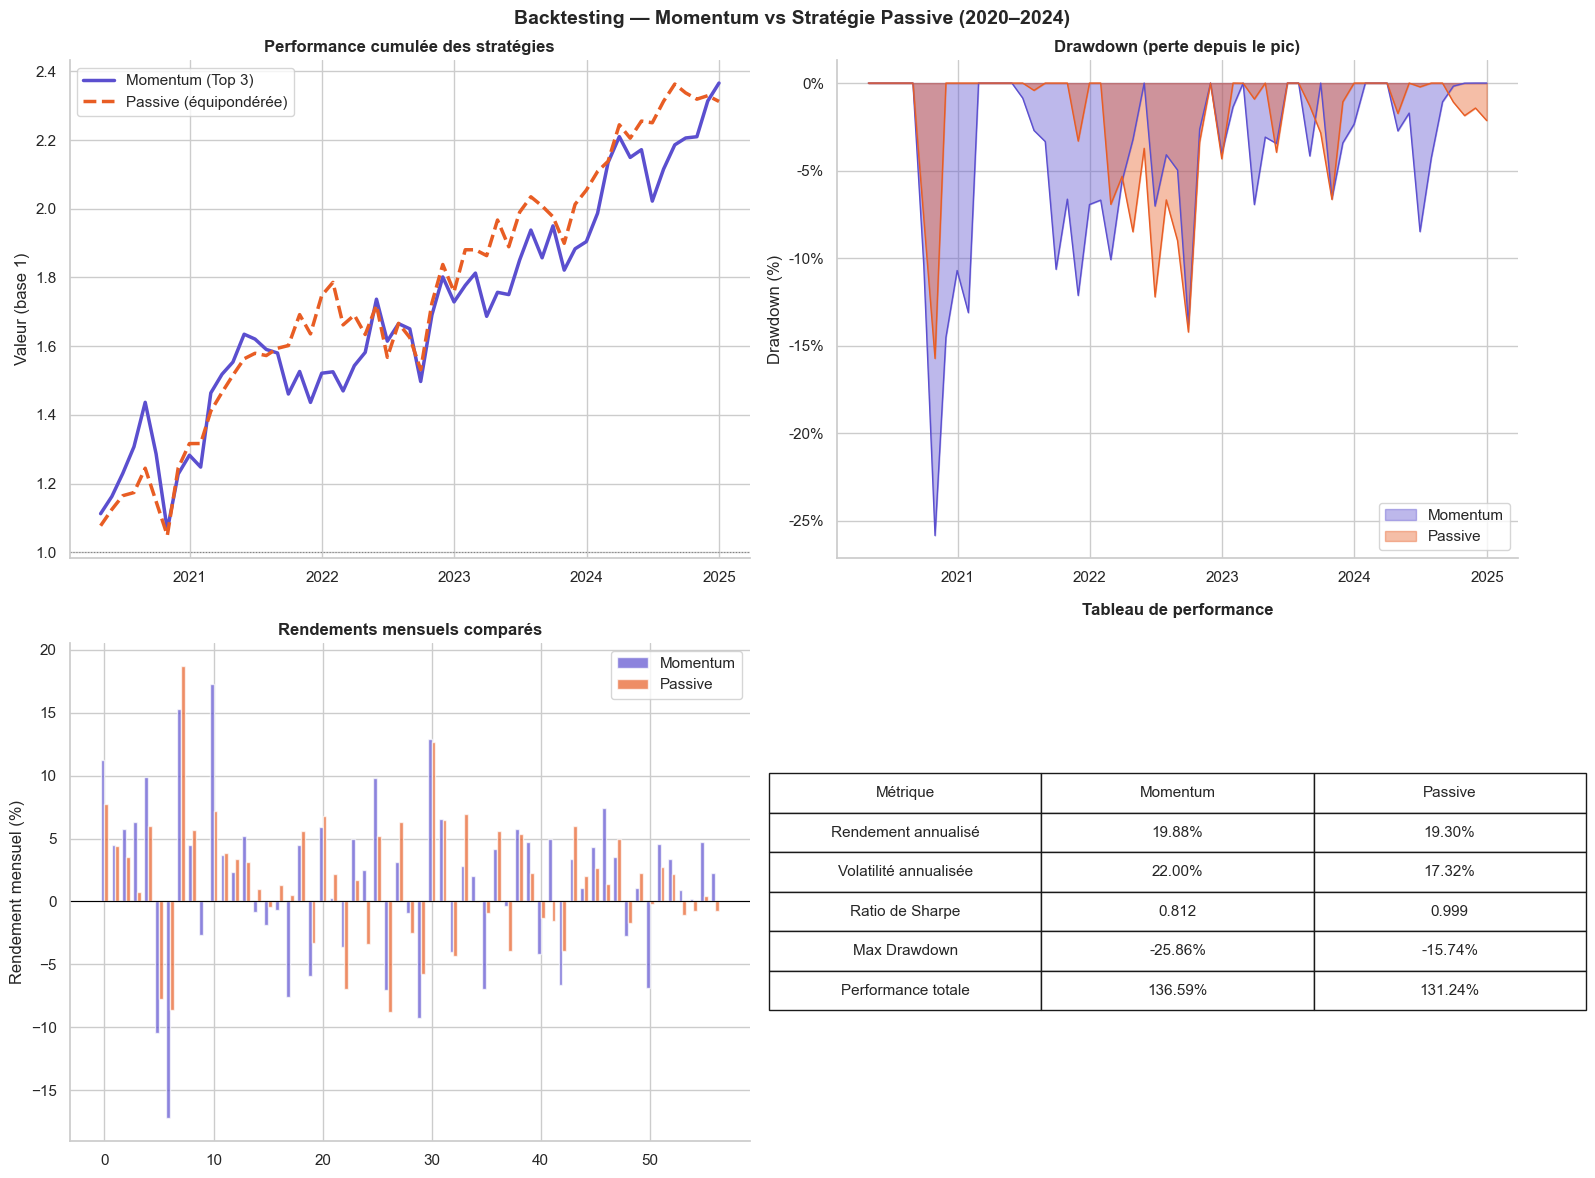

In [15]:
# Visualisations backtesting
cumul_mom = (1 + bt['momentum']).cumprod()
cumul_pas = (1 + bt['passive']).cumprod()

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Performance cumulée
ax = axes[0, 0]
ax.plot(cumul_mom.index, cumul_mom, color='#5B4FCF', linewidth=2.5,
        label='Momentum (Top 3)')
ax.plot(cumul_pas.index, cumul_pas, color='#E85D24', linewidth=2.5,
        linestyle='--', label='Passive (équipondérée)')
ax.axhline(y=1, color='gray', linewidth=0.8, linestyle=':')
ax.set_title('Performance cumulée des stratégies', fontweight='bold')
ax.set_ylabel('Valeur (base 1)')
ax.legend()

# 2. Drawdown
ax2 = axes[0, 1]
for strat, color, label in [
    ('momentum', '#5B4FCF', 'Momentum'),
    ('passive', '#E85D24', 'Passive')
]:
    cumul = (1 + bt[strat]).cumprod()
    dd = (cumul - cumul.cummax()) / cumul.cummax()
    ax2.fill_between(dd.index, dd, 0, alpha=0.4, color=color, label=label)
    ax2.plot(dd.index, dd, color=color, linewidth=1)
ax2.set_title('Drawdown (perte depuis le pic)', fontweight='bold')
ax2.set_ylabel('Drawdown (%)')
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
ax2.legend()

# 3. Rendements mensuels
ax3 = axes[1, 0]
x = np.arange(len(bt))
w = 0.35
ax3.bar(x - w/2, bt['momentum'] * 100, w, color='#5B4FCF', alpha=0.7, label='Momentum')
ax3.bar(x + w/2, bt['passive']  * 100, w, color='#E85D24', alpha=0.7, label='Passive')
ax3.axhline(y=0, color='black', linewidth=0.8)
ax3.set_title('Rendements mensuels comparés', fontweight='bold')
ax3.set_ylabel('Rendement mensuel (%)')
ax3.legend()

# 4. Tableau récapitulatif
ax4 = axes[1, 1]
ax4.axis('off')
table_data = comparaison.reset_index().values
table = ax4.table(
    cellText=table_data,
    colLabels=['Métrique', 'Momentum', 'Passive'],
    cellLoc='center', loc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 2)
ax4.set_title('Tableau de performance', fontweight='bold', pad=20)

plt.suptitle('Backtesting — Momentum vs Stratégie Passive (2020–2024)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('backtesting.png', dpi=150, bbox_inches='tight')
plt.show()


### Observations — Backtesting Momentum vs Passive

- Résultat contre-intuitif : la stratégie passive bat la momentum 
  sur le Sharpe (0.999 vs 0.812) malgré un rendement légèrement 
  inférieur (+19.30% vs +19.88%)
- Explication : la momentum prend 27% de volatilité en plus 
  (22% vs 17.32%) pour un gain marginal de +0.58%/an — 
  rapport risque/rendement défavorable
- Max Drawdown momentum (-25.86%) bien supérieur à la passive 
  (-15.74%) : la momentum est dangereuse en période de retournement
- Limites du backtesting :
  1. Pas de frais de transaction (la momentum tourne le portefeuille 
     chaque mois → coûts réels significatifs)
  2. Look-ahead bias : on optimise sur des données passées
  3. Fenêtre 2020-2024 favorable aux marchés haussiers — 
     résultats différents sur une période de crise prolongée
- Conclusion business : sur ce portefeuille et cette période, 
  investir passivement est plus efficace que timer le marché 
  avec une stratégie momentum simple

> 
### Portefeuille Markowitz
- Allocation optimale : Apple (61.5%), TotalEnergies (29.2%), SAP (9.3%) — 
  5 actions éliminées car rendement insuffisant ou trop corrélées entre elles
- Ratio de Sharpe optimal : 0.776 (rendement 21.2%, volatilité 24.7%)
- Observation sur la diversification Europe/USA : Markowitz sélectionne 
  naturellement un mix géographique (1 US tech, 1 énergie européenne, 1 tech 
  allemande) grâce à leurs faibles corrélations (Apple/TotalEnergies = 0.33, 
  TotalEnergies/SAP = 0.18). JPMorgan et BNP Paribas éliminés malgré de bonnes 
  propriétés de diversification — rendement sur 5 ans trop faible (+1.8% et +11.9%)

### Mesure du risque
- VaR 95% journalière : 2.26% → 2 262€ sur 100 000€ 
  (1 jour sur 20, la perte dépasse ce seuil)
- CVaR 95% journalière : 3.65% → 3 652€ sur 100 000€ 
  (perte moyenne dans les 5% pires jours — 60% au-dessus de la VaR, 
  signe de queues épaisses / fat tails)
- Simulation Monte Carlo à 1 an (10 000 scénarios sur 100 000€) :
  - Valeur médiane : 119 660€ (+19.7%)
  - Meilleur cas (99%) : 212 023€ (+112%)
  - Pire cas (1%) : 67 309€ (-32.7%)
  - VaR annuelle 95% : 20 700€
  - CVaR annuelle 95% : 28 150€

### Backtesting momentum (2020–2024, 57 mois)
- La stratégie passive bat la momentum sur le Sharpe (0.999 vs 0.812) 
  malgré un rendement total légèrement inférieur (+131.24% vs +136.59%)
- La momentum prend 27% de volatilité en plus (22% vs 17.32%) 
  pour un gain marginal de +0.58%/an — rapport risque/rendement défavorable
- Max Drawdown momentum : -25.86% vs -15.74% pour la passive — 
  la momentum est significativement plus risquée en période de retournement
- Momentum performe mieux : rebond post-COVID (2020-2021), 
  marchés fortement directionnels
- Momentum performe moins bien : 2022 (hausse des taux, 
  rotations sectorielles rapides), périodes de forte volatilité

### Limites du modèle
- L'optimisation Markowitz suppose que les rendements passés prédisent 
  les rendements futurs (instabilité de la matrice de covariance)
- Le backtesting ne prend pas en compte les frais de transaction 
  (la momentum tourne le portefeuille chaque mois → coûts réels significatifs)
- La distribution normale sous-estime les événements extrêmes 
  (queues épaisses / fat tails confirmés : CVaR = 1.6 × VaR)
- La concentration Markowitz (61.5% Apple) est irréaliste en pratique — 
  les réglementations imposent des limites de concentration (~20-30% max)
- Fenêtre 2020-2024 favorable aux marchés haussiers — 
  résultats pourraient différer sur une période de crise prolongée

---
*Ce projet couvre les bases de la gestion quantitative de portefeuille 
utilisées en Asset Management et Risk Management. Les techniques de VaR/CVaR 
et de stress testing sont directement applicables aux exigences Bâle III 
pour le calcul du capital réglementaire des banques.*